In [1]:
import duckdb
con = duckdb.connect("rfm.duckdb")

In [2]:
# Run once to load the CSV. Already saved in rfm.duckdb.
# con.sql("""
#     CREATE OR REPLACE TABLE sales AS
#     SELECT * FROM read_csv_auto('_data/online_retail.csv')
# """)
con.sql("DESCRIBE sales").df()

,column_name,column_type,null,key,default,extra
0,Invoice,VARCHAR,YES,None,None,None
1,StockCode,VARCHAR,YES,None,None,None
2,Description,VARCHAR,YES,None,None,None
3,Quantity,BIGINT,YES,None,None,None
4,InvoiceDate,TIMESTAMP,YES,None,None,None
5,Price,DOUBLE,YES,None,None,None
6,Customer ID,DOUBLE,YES,None,None,None
7,Country,VARCHAR,YES,None,None,None


In [3]:
con.sql("SELECT COUNT(*) AS total_rows FROM sales").df()

,total_rows
0,1067371


In [4]:
con.sql("SELECT MIN(InvoiceDate) AS first_date, MAX(InvoiceDate) AS last_date FROM sales").df()

,first_date,last_date
0,2009-12-01 07:45:00,2011-12-09 12:50:00


In [5]:
con.sql('SELECT COUNT(*) AS no_customer FROM sales WHERE "Customer ID" IS NULL').df()

,no_customer
0,243007


In [6]:
con.sql("SELECT COUNT(*) AS cancellations FROM sales WHERE Invoice LIKE 'C%'").df()

,cancellations
0,19494


In [7]:
con.sql("SELECT COUNT(*) AS bad_rows FROM sales WHERE Quantity <= 0 OR Price <= 0").df()

,bad_rows
0,25700


**Findings**
- 1,067,371 rows, Dec 2009 to Dec 2011
- 22.8% have no customer ID: removed, since RFM needs a customer
- 19,494 cancellation rows (invoice starts with C) and 25,700 rows with zero or negative quantity or price: removed

In [8]:
con.sql("""
SELECT Invoice, InvoiceDate, Quantity, Price, Quantity * Price AS line_total
FROM sales
WHERE "Customer ID" = 16446
ORDER BY InvoiceDate
""").df()

,Invoice,InvoiceDate,Quantity,Price,line_total
0,C525275,2010-10-04 16:38:00,-2,4.50,-9.00
1,553573,2011-05-18 09:52:00,1,1.65,1.65
2,553573,2011-05-18 09:52:00,1,1.25,1.25
3,581483,2011-12-09 09:15:00,80995,2.08,168469.60
4,C581484,2011-12-09 09:27:00,-80995,2.08,-168469.60


**Finding:** some orders were later fully cancelled (e.g. customer 16446: 168k order cancelled 12 minutes later). Removing only the "C" rows left the original order counting as spend, so I also remove orders with a matching cancellation.

In [9]:
con.sql("""
create or replace table clean_sales AS
select 
 invoice, 
 invoicedate, 
 CAST("Customer ID" AS INTEGER) AS customer_id,
 Quantity,
 Price, 
 Quantity * Price AS revenue
from sales s 
where s."customer ID" IS NOT NULL
  and s.Quantity > 0
  and s.Price > 0
  and s.Invoice not like 'C%'
and not exists (
    select 1 from sales c
    where c.invoice like 'C%' 
    and c."Customer ID" = s."Customer ID"
    and c.stockcode = s.stockcode
    and c.quantity = -s.quantity
    and c.invoicedate >= s.invoicedate)""")


CountBIGINT
795637


In [10]:
con.sql(""" 
select COUNT(*) AS rows_left, 
    COUNT(DISTINCT customer_id) AS customers,
    min(revenue) AS min_revenue
from clean_sales
  """).df()

,rows_left,customers,min_revenue
0,795637,5850,0.001


In [11]:
con.sql("""create or replace table rfm AS
select 
    customer_id,
    Round(sum(revenue), 2) AS monetary,
    count(distinct invoice) AS frequency,
    DATE_DIFF('day', max(invoicedate), TIMESTAMP '2011-12-10') AS recency
from clean_sales 
group by customer_id
""")

CountBIGINT
5850


In [12]:
con.sql(" select * from rfm order by monetary desc limit 10").df()

,customer_id,monetary,frequency,recency
0,18102,606963.25,145,1
1,14646,521424.26,146,2
2,14156,298274.92,149,10
3,14911,262975.46,374,2
4,17450,235864.75,49,9
5,13694,191445.63,141,4
6,17511,156230.55,58,3
7,12415,143350.72,26,25
8,16684,141193.97,53,5
9,15061,136969.28,126,4


In [13]:
con.sql("SELECT * FROM rfm WHERE customer_id = 16446").df()

,customer_id,monetary,frequency,recency
0,16446,2.9,1,206


In [14]:
con.sql("""
CREATE OR REPLACE TABLE rfm_scores AS
SELECT
    customer_id, recency, frequency, monetary,
    NTILE(5) OVER (ORDER BY recency DESC,  customer_id) AS r_score,
    NTILE(5) OVER (ORDER BY frequency ASC, customer_id) AS f_score,
    NTILE(5) OVER (ORDER BY monetary ASC,  customer_id) AS m_score
FROM rfm
""")

CountBIGINT
5850


In [15]:
con.sql("""
SELECT r_score, COUNT(*) AS customers, MIN(recency) AS min_days, MAX(recency) AS max_days
FROM rfm_scores
GROUP BY r_score
ORDER BY r_score
""").df()

,r_score,customers,min_days,max_days
0,1,1170,410,739
1,2,1170,188,410
2,3,1170,59,188
3,4,1170,20,59
4,5,1170,1,20


In [16]:
con.sql("""
CREATE OR REPLACE TABLE rfm_segments AS
SELECT *,
    CASE
        WHEN r_score >= 4 AND f_score >= 4 THEN 'Champions'
        WHEN r_score >= 3 AND f_score >= 3 THEN 'Loyal Customers'
        WHEN r_score >= 4 AND f_score <= 2 THEN 'Potential Loyalists'
        WHEN r_score = 3  AND f_score <= 2 THEN 'Needs Attention'
        WHEN r_score <= 2 AND f_score >= 4 THEN 'Cant Lose Them'
        WHEN r_score <= 2 AND f_score = 3  THEN 'At Risk'
        WHEN r_score <= 2 AND f_score <= 2 THEN 'Hibernating'
        ELSE 'Other'
    END AS segment
FROM rfm_scores
""")

CountBIGINT
5850


In [17]:
con.sql("""
SELECT
    segment,
    COUNT(*) AS customers,
    ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct_customers,
    ROUND(SUM(monetary)) AS revenue,
    ROUND(100.0 * SUM(monetary) / SUM(SUM(monetary)) OVER (), 1) AS pct_revenue
FROM rfm_segments
GROUP BY segment
ORDER BY revenue DESC
""").df()

,segment,customers,pct_customers,revenue,pct_revenue
0,Champions,1468,25.1,11854173.0,70.2
1,Loyal Customers,1222,20.9,2489265.0,14.7
2,Cant Lose Them,353,6.0,1006360.0,6.0
3,Hibernating,1520,26.0,668284.0,4.0
4,At Risk,467,8.0,442194.0,2.6
5,Potential Loyalists,438,7.5,225354.0,1.3
6,Needs Attention,382,6.5,203856.0,1.2


In [18]:
with open("queries.sql") as f:
    final = con.sql(f.read()).df()

step_by_step = con.sql("SELECT * FROM rfm_segments").df()

print(len(final), len(step_by_step))
print(final.sort_values("customer_id").reset_index(drop=True)[["customer_id", "segment"]].equals(
      step_by_step.sort_values("customer_id").reset_index(drop=True)[["customer_id", "segment"]]))

5850 5850
True


In [19]:
a = final.set_index("customer_id")
b = step_by_step.set_index("customer_id").loc[a.index]
diff = a[a["segment"] != b["segment"]]
print(len(diff), "customers differ")
print(a.loc[diff.index, ["recency","frequency","monetary","r_score","f_score"]].head())

0 customers differ
Empty DataFrame
Columns: [recency, frequency, monetary, r_score, f_score]
Index: []


## Results: who are our customers?

In [20]:
import seaborn as sns 
import matplotlib.pyplot as plt

summary = con.sql("""
SELECT segment, 
        COUNT(*) AS customers,
        ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct_customers,
        ROUND(100.0 * SUM(monetary) / SUM(SUM(monetary)) OVER (), 1) AS pct_revenue
from rfm_segments
GROUP BY segment
ORDER BY pct_revenue DESC
""").df()
summary

,segment,customers,pct_customers,pct_revenue
0,Champions,1468,25.1,70.2
1,Loyal Customers,1222,20.9,14.7
2,Cant Lose Them,353,6.0,6.0
3,Hibernating,1520,26.0,4.0
4,At Risk,467,8.0,2.6
5,Potential Loyalists,438,7.5,1.3
6,Needs Attention,382,6.5,1.2


Customers are scored 1 to 5 on Recency, Frequency and Monetary value, then grouped into 7 segments based on recency and frequency. The two charts below use the same segment order, so you can compare each segment's share of customers with its share of revenue.

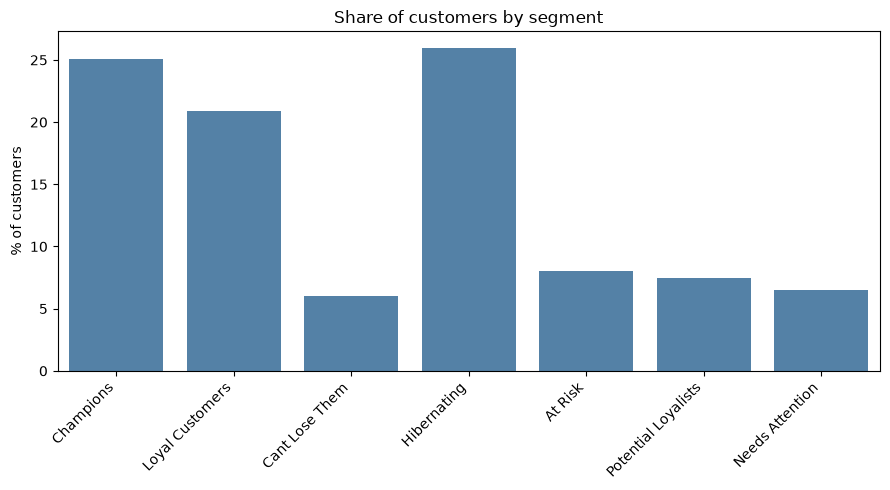

In [21]:
plt.figure(figsize=(9, 5))
sns.barplot(data=summary, x="segment", y="pct_customers", color="steelblue", order=summary["segment"])
plt.title("Share of customers by segment")
plt.ylabel("% of customers")
plt.xlabel("")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("chart_customers.png", dpi=150)
plt.show()

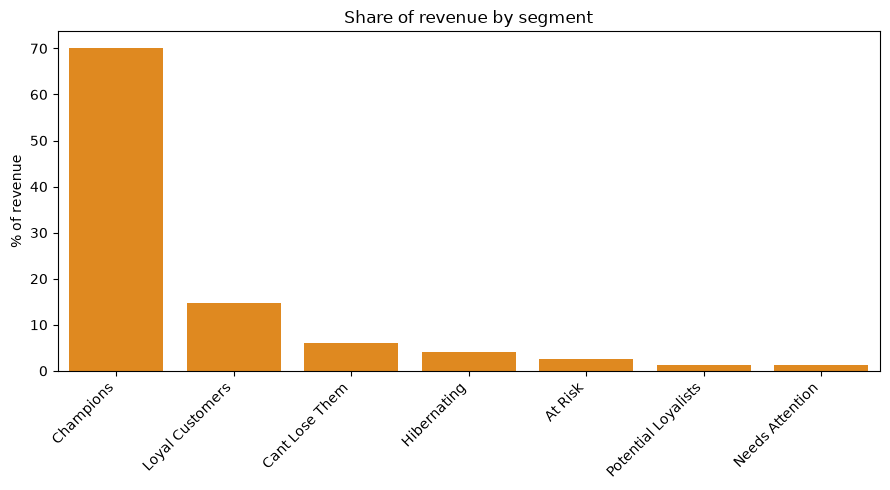

In [22]:
plt.figure(figsize=(9, 5))
sns.barplot(data=summary, x="segment", y="pct_revenue", color="darkorange", order=summary["segment"])
plt.title("Share of revenue by segment")
plt.ylabel("% of revenue")
plt.xlabel("")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("chart_revenue.png", dpi=150)
plt.show()

### Key findings

- **Champions** are 25.1% of customers but generate **70.2% of revenue**. Losing a few of them costs far more than losing many other customers.
- **Champions + Loyal Customers** together are 46% of customers and about **85% of revenue**.
- **Cant Lose Them** (6.0% of customers, 6.0% of revenue) are frequent buyers who have gone quiet. They are the best win-back target.
- **Hibernating** customers are the largest group (26.0%) but bring only 4.0% of revenue, so heavy marketing spend on them has low payoff.
- **At Risk, Potential Loyalists and Needs Attention** are each 1-3% of revenue. They are small individually, and the focus should stay on retaining Champions and recovering Cant Lose Them.

*Limitation: ties in frequency are split by customer_id, so segment boundaries are approximate for customers with identical values.*